# Notebook 02 — Clustering Experiments

**Project:** AI-Powered Sustainable Infrastructure Investment Intelligence: A Decision Support Framework for Africa's AI Readiness

## 1. Objectives and Experimental Design

This notebook investigates whether African urban centres can be grouped into meaningful infrastructure-readiness profiles using unsupervised machine learning. The analysis covers 2,172 urban centres and draws on socioeconomic, infrastructure, connectivity and environmental indicators.

Two feature configurations will be evaluated:

- **Baseline (12 predictors):** Eleven GHSL indicators and one ITU terrestrial fibre proximity indicator.
- **Extended (13 predictors):** The baseline indicators plus PeeringDB facility counts.

K-Means and Agglomerative Hierarchical Clustering will be compared using appropriate cluster-quality metrics, stability assessments and substantive interpretability. Alternative transformations and scaling approaches will be evaluated before final model selection.

The objective is to identify interpretable urban infrastructure profiles that can inform differentiated investment priorities, rather than treating cluster membership as a direct measure of investment suitability.

PeeringDB will additionally support external interpretation of the baseline clusters, recognizing that its coverage is incomplete and highly sparse.

**Input dataset:** `data/processed/africa_ai_readiness_analytical.csv`

**Preprocessing principle:** Preserve the original imputed values and apply transformations and scaling within clearly documented experimental configurations.

### Load and Validate the Analytical Dataset

In [1]:

import pandas as pd
from pathlib import Path

# Load the prepared analytical dataset
data_path = Path("../data/processed/africa_ai_readiness_analytical.csv")
df = pd.read_csv(data_path)

# Verify dataset dimensions and identifiers
print("Dataset shape:", df.shape)
print("Unique urban centres:", df["ID_UC_G0"].nunique())
print("Duplicate IDs:", df["ID_UC_G0"].duplicated().sum())
print("Total missing values:", df.isna().sum().sum())

# Preview the dataset
display(df.head())


Dataset shape: (2172, 16)
Unique urban centres: 2172
Duplicate IDs: 0
Total missing values: 0


,ID_UC_G0,GC_UCN_MAI_2025,GC_CNT_GAD_2025,GH_POP_TOT_2025,SC_GDP_AVG_2020,IN_CIS_ENE_2020,IN_CIS_TEL_2020,fibre_distance_band_km,IN_CIS_TRA_2020,IN_ROA_DEN_2024,SC_SEC_SYT_2020,IN_CIS_EDU_2020,IN_CIS_WAT_2020,CL_REN_PVO_2020,CL_B01_CUR_2010,peeringdb_facility_count
0,38,Mindelo,Cabo Verde,8.827388e+04,24662104.38,2.620000e-08,2.460000e-07,15,0.002402,0.013276,6.713000,0.000719,6.260000e-09,4.327,23.108,0
1,39,Dakar,Senegal,3.970202e+06,62829932.16,2.131755e-02,1.385724e-03,10,0.038976,0.020983,5.047000,0.020982,1.617000e-04,4.747,24.496,2
2,40,Serrekunda,Gambia,1.313465e+06,13591185.78,4.863860e-04,1.402762e-03,5,0.012696,0.014302,5.764927,0.004661,5.970000e-05,4.672,25.180,0
3,41,Nouadhibou,Mauritania,1.774690e+05,28353481.96,1.800000e-05,5.439420e-04,5,0.006597,0.011540,9.137000,0.000048,3.690000e-06,5.101,20.147,0
4,43,Bissau,Guinea-Bissau,6.744443e+05,18002209.03,0.000000e+00,2.830000e-06,5,0.006249,0.008329,6.934985,0.000695,0.000000e+00,4.519,26.630,0


### Define Clustering Feature Configurations

In [2]:

# Separate identification fields from numerical predictors
id_columns = [
    "ID_UC_G0",
    "GC_UCN_MAI_2025",
    "GC_CNT_GAD_2025"
]

# Unified 13-feature matrix
X_unified = df.drop(columns=id_columns).copy()

# Configuration A: Baseline (12 features)
X_baseline = X_unified.drop(
    columns=["peeringdb_facility_count"]
)

# Configuration B: Extended (13 features)
X_extended = X_unified.copy()

# Verify both configurations
print("Baseline shape:", X_baseline.shape)
print("Extended shape:", X_extended.shape)
print("All predictors numeric:",
      all(pd.api.types.is_numeric_dtype(t) for t in X_unified.dtypes))
print("Missing predictor values:", X_unified.isna().sum().sum())


Baseline shape: (2172, 12)
Extended shape: (2172, 13)
All predictors numeric: True
Missing predictor values: 0



### Clustering Evaluation and Validation Strategy

#### Methodological Rationale

Unlike supervised machine learning, which learns relationships between predictors and known target labels, this study applies unsupervised clustering to discover infrastructure-readiness profiles among 2,172 African urban centres. No verified target labels exist in the analytical dataset to define objectively correct readiness categories. Consequently, conventional predictive evaluation procedures, such as a fixed training/testing split followed by classification accuracy or prediction-error assessment, are not directly applicable to the primary research objective.

A conventional holdout split was considered but is not adopted for the main exploratory analysis. Instead, the study uses the complete analytical dataset to identify and characterize urban infrastructure patterns, supported by complementary assessments of cluster quality, stability, preprocessing robustness and substantive interpretability. This approach preserves coverage of the study population while recognizing that clustering results represent data-derived groupings rather than independently verified readiness classes.

#### Evaluation Framework

Four complementary evaluation dimensions will be considered:

1. **Internal cluster quality:** Silhouette Score and Davies–Bouldin Index will assess cluster cohesion and separation. These metrics will support comparisons across algorithms and candidate numbers of clusters but will not be interpreted as measures of investment suitability or predictive accuracy.

2. **Cluster stability:** Repeated clustering and subsampling will assess whether broadly consistent groupings emerge under reasonable changes in initialization or sample composition. Where appropriate, the Adjusted Rand Index (ARI) will compare cluster assignments for common observations.

3. **Preprocessing robustness:** Alternative, theoretically justified transformation and scaling strategies will be compared to assess their influence on cluster structure. Data-dependent preprocessing parameters will be fitted within the relevant analysis or resampling procedure to avoid inappropriate information sharing across evaluation samples.

4. **External interpretation and substantive validity:** Cluster profiles will be examined in relation to infrastructure, socioeconomic, connectivity and environmental characteristics. PeeringDB facility counts, excluded from the 12-predictor baseline configuration, will provide supplementary external evidence for interpreting baseline clusters. Given PeeringDB's incomplete and highly sparse coverage, facility counts will not be treated as ground-truth readiness labels. For the 13-predictor extended configuration, PeeringDB cannot constitute independent validation evidence because it contributes directly to cluster formation.

#### Model Selection and Interpretation

K-Means and Agglomerative Hierarchical Clustering will be compared across a reasonable range of cluster numbers and selected preprocessing configurations. Model selection will consider internal evaluation metrics, stability, robustness and the substantive interpretability of resulting urban profiles rather than optimizing a single numerical score.

The study distinguishes exploratory model selection from independent out-of-sample validation. Internal metrics calculated on observations used to construct clusters are descriptive measures of clustering quality, not estimates of predictive generalization performance. Stability assessments provide additional evidence of robustness but do not establish objectively correct cluster membership.

The final clusters will therefore be interpreted as **exploratory infrastructure-readiness profiles** that can inform differentiated investment analysis, rather than as validated predictions of investment success or definitive measures of AI readiness.


## Preprocessing and Scaling Strategy

### Assessing Logarithmic Transformations

,Original_Skewness,Log10_Skewness
GH_POP_TOT_2025,13.113,1.774
SC_GDP_AVG_2020,3.000,0.001


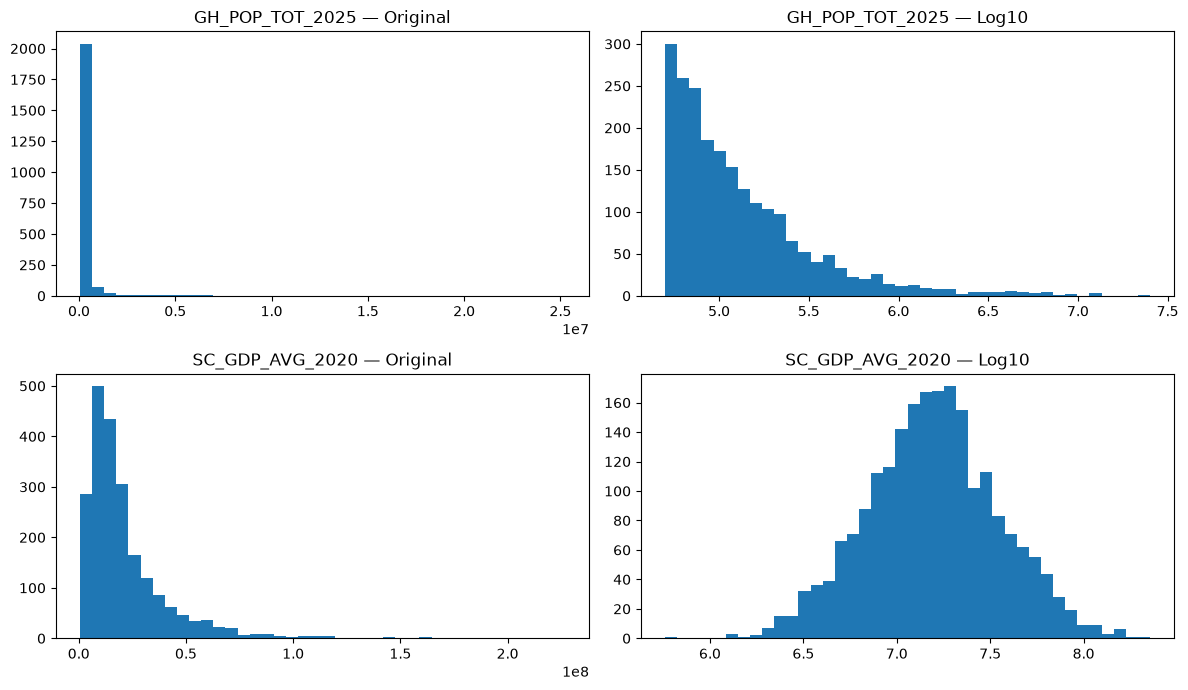

In [3]:

import numpy as np
import matplotlib.pyplot as plt

# Create a separate copy for transformation experiments
X_transformed = X_baseline.copy()

# Apply logarithmic transformation to positive-valued variables
log_features = ["GH_POP_TOT_2025", "SC_GDP_AVG_2020"]

for col in log_features:
    X_transformed[col] = np.log10(X_transformed[col])

# Compare skewness before and after transformation
comparison = pd.DataFrame({
    "Original_Skewness": X_baseline[log_features].skew(),
    "Log10_Skewness": X_transformed[log_features].skew()
})

display(comparison.round(3))

# Compare original and transformed distributions
fig, axes = plt.subplots(2, 2, figsize=(12, 7))

for i, col in enumerate(log_features):
    axes[i, 0].hist(X_baseline[col], bins=40)
    axes[i, 0].set_title(f"{col} — Original")

    axes[i, 1].hist(X_transformed[col], bins=40)
    axes[i, 1].set_title(f"{col} — Log10")

plt.tight_layout()
plt.show()



#### Logarithmic Transformation — Findings

The distributions of urban population and spatial GDP were examined before and after base-10 logarithmic transformation. Population skewness decreased from 13.113 to 1.774, while GDP skewness decreased from 3.000 to approximately 0.001.

The transformation substantially reduced the influence of extreme values, particularly for GDP, without removing observations. Population remained moderately right-skewed, reflecting the considerable variation in urban-centre sizes across Africa.

Both variables are therefore retained as candidates for logarithmic transformation in the initial clustering preprocessing configuration. Their final suitability will be assessed alongside scaling choices and cluster robustness. The original, imputed values remain unchanged in the source analytical dataset.


### Assessing Infrastructure Index Transformations

In [4]:

# Infrastructure indicators
infrastructure_features = [
    "IN_CIS_ENE_2020",
    "IN_CIS_TEL_2020",
    "IN_CIS_TRA_2020",
    "IN_CIS_EDU_2020",
    "IN_CIS_WAT_2020"
]

# Compare original and transformed distributions
infrastructure_comparison = []

for col in infrastructure_features:
    original = X_baseline[col]

    # Use the median of strictly positive observations
    positive_median = original[original > 0].median()

    # Exploratory transformation; original data remain unchanged
    transformed = np.log1p(original / positive_median)

    infrastructure_comparison.append({
        "Feature": col,
        "Original_Skewness": original.skew(),
        "Transformed_Skewness": transformed.skew(),
        "Zero_Percent": (original == 0).mean() * 100
    })

infrastructure_comparison = pd.DataFrame(
    infrastructure_comparison
).set_index("Feature")

display(infrastructure_comparison.round(3))


,Original_Skewness,Transformed_Skewness,Zero_Percent
Feature,,,
IN_CIS_ENE_2020,1.953,0.884,33.794
IN_CIS_TEL_2020,5.454,1.834,54.052
IN_CIS_TRA_2020,3.017,0.943,0.046
IN_CIS_EDU_2020,6.765,1.672,40.470
IN_CIS_WAT_2020,22.260,4.180,71.915



#### Infrastructure Index Transformation — Findings

Five GHSL infrastructure indices (energy, telecommunications, transportation, education and water) were assessed using a zero-preserving logarithmic transformation, `log1p(x / m)`, where `m` represents the median of strictly positive observations for each indicator.

The transformation reduced skewness across all five indices: energy (1.953 to 0.884), telecommunications (5.454 to 1.834), transportation (3.017 to 0.943), education (6.765 to 1.672) and water (22.260 to 4.180).

These results suggest that the transformation may reduce the influence of extreme values while preserving the original zero observations. However, substantial zero concentrations remain, particularly for water (71.92%), telecommunications (54.05%) and education (40.47%). Consequently, reduced skewness alone does not establish that the transformed variables are optimal for distance-based clustering.

The transformation is retained as a candidate preprocessing strategy, subject to comparison with alternative scaling approaches and assessment of cluster quality, stability and interpretability. The original analytical dataset remains unchanged. The positive-median reference values must be re-estimated within each resampling procedure when conducting stability assessments.


## Prepare the transformed feature matrix

### Scaling Strategy Assessment

In [5]:

from sklearn.preprocessing import StandardScaler, RobustScaler

# Start from the original baseline configuration
X_prepared = X_baseline.copy()

# Population and GDP: base-10 logarithmic transformation
log_features = ["GH_POP_TOT_2025", "SC_GDP_AVG_2020"]

for col in log_features:
    X_prepared[col] = np.log10(X_prepared[col])

# Infrastructure indices: zero-preserving logarithmic transformation
infrastructure_features = [
    "IN_CIS_ENE_2020",
    "IN_CIS_TEL_2020",
    "IN_CIS_TRA_2020",
    "IN_CIS_EDU_2020",
    "IN_CIS_WAT_2020"
]

for col in infrastructure_features:
    positive_median = X_baseline.loc[
        X_baseline[col] > 0, col
    ].median()

    X_prepared[col] = np.log1p(
        X_baseline[col] / positive_median
    )

# Confirm the original matrix remains unchanged
print("Prepared shape:", X_prepared.shape)
print("Missing values:", X_prepared.isna().sum().sum())
print("Original baseline shape:", X_baseline.shape)


Prepared shape: (2172, 12)
Missing values: 0
Original baseline shape: (2172, 12)


## Compare StandardScaler and RobustScaler

In [6]:

# Apply alternative scaling strategies
standard_scaler = StandardScaler()
robust_scaler = RobustScaler()

X_standard = pd.DataFrame(
    standard_scaler.fit_transform(X_prepared),
    columns=X_prepared.columns,
    index=X_prepared.index
)

X_robust = pd.DataFrame(
    robust_scaler.fit_transform(X_prepared),
    columns=X_prepared.columns,
    index=X_prepared.index
)

# Compare feature dispersion after scaling
scaling_comparison = pd.DataFrame({
    "StandardScaler_Std": X_standard.std(),
    "RobustScaler_Std": X_robust.std(),
    "StandardScaler_IQR": (
        X_standard.quantile(0.75) -
        X_standard.quantile(0.25)
    ),
    "RobustScaler_IQR": (
        X_robust.quantile(0.75) -
        X_robust.quantile(0.25)
    )
})

display(scaling_comparison.round(3))


,StandardScaler_Std,RobustScaler_Std,StandardScaler_IQR,RobustScaler_IQR
GH_POP_TOT_2025,1.0,0.885,1.130,1.0
SC_GDP_AVG_2020,1.0,0.765,1.307,1.0
IN_CIS_ENE_2020,1.0,0.640,1.562,1.0
IN_CIS_TEL_2020,1.0,1.021,0.979,1.0
fibre_distance_band_km,1.0,0.760,1.316,1.0
IN_CIS_TRA_2020,1.0,0.737,1.356,1.0
IN_ROA_DEN_2024,1.0,0.725,1.379,1.0
SC_SEC_SYT_2020,1.0,0.569,1.757,1.0
IN_CIS_EDU_2020,1.0,0.880,1.136,1.0
IN_CIS_WAT_2020,1.0,40.128,0.025,1.0



### Scaling Strategy Assessment — Findings

StandardScaler and RobustScaler were compared using the transformed 12-feature baseline dataset comprising 2,172 African urban centres.

StandardScaler produced approximately equal standard deviations across all predictors. RobustScaler produced greater variation in feature dispersion, particularly for the water infrastructure index (`IN_CIS_WAT_2020`), whose standard deviation increased to approximately 40.13 after scaling.

This behaviour is associated with the highly zero-concentrated distribution of the water infrastructure indicator (approximately 72% zero observations), resulting in a very small interquartile range. Consequently, RobustScaler may disproportionately amplify this predictor's contribution to Euclidean distances.

StandardScaler is therefore selected as the initial scaling strategy for clustering experiments, while RobustScaler is retained for sensitivity analysis. The final preprocessing configuration will be evaluated using cluster quality, stability and interpretability rather than scaling statistics alone.

The original analytical dataset remains unchanged. All transformations and scaling operations are performed on separate experimental feature matrices.



## Initial K-Means Clustering Experiment

K-Means clustering is applied to the 12-feature baseline configuration using the selected transformation strategy and StandardScaler.

Candidate solutions ranging from 2 to 10 clusters are evaluated using three complementary criteria:

- **Silhouette Score:** Measures cluster cohesion and separation. Higher values indicate better-defined clusters.
- **Davies–Bouldin Index:** Measures similarity between clusters relative to their internal dispersion. Lower values are preferred.
- **Inertia:** Measures within-cluster squared distances and supports assessment of diminishing improvements as the number of clusters increases.

The objective is to identify a reasonable range of cluster solutions for further stability assessment and substantive interpretation. No single metric will determine the final number of clusters.


In [7]:

import pandas as pd
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score

# Evaluate candidate numbers of clusters
k_values = range(2, 11)
kmeans_results = []

for k in k_values:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20
    )

    labels = model.fit_predict(X_standard)

    kmeans_results.append({
        "k": k,
        "Silhouette_Score": silhouette_score(X_standard, labels),
        "Davies_Bouldin_Index": davies_bouldin_score(X_standard, labels),
        "Inertia": model.inertia_,
        "Smallest_Cluster": pd.Series(labels).value_counts().min()
    })

kmeans_results_df = pd.DataFrame(kmeans_results)

display(kmeans_results_df.round(3))


,k,Silhouette_Score,Davies_Bouldin_Index,Inertia,Smallest_Cluster
0,2,0.250,1.705,20000.868,747
1,3,0.206,1.799,18068.076,270
2,4,0.163,1.831,16255.865,245
3,5,0.178,1.752,14747.921,245
4,6,0.184,1.643,13943.553,69
5,7,0.176,1.686,13205.307,69
6,8,0.166,1.734,12600.772,66
7,9,0.165,1.751,12061.425,62
8,10,0.169,1.708,11603.523,52



### Interpretation of Initial K-Means Results

The initial K-Means experiment revealed moderate-to-weak cluster separation, with Silhouette Scores ranging from 0.163 to 0.250. The two-cluster solution (k = 2) achieved the highest Silhouette Score (0.250), suggesting the clearest broad differentiation among urban centres, while the six-cluster solution (k = 6) achieved the lowest Davies–Bouldin Index (1.643), indicating comparatively favourable cluster compactness and separation under this metric. The three-cluster solution (k = 3) offers an intermediate alternative with relatively balanced cluster sizes. These findings suggest that African urban infrastructure characteristics may exhibit overlapping rather than sharply separated profiles. Consequently, no optimal cluster number is selected at this stage; further assessment of cluster stability, preprocessing sensitivity and substantive interpretability is required.


### Visualize the evaluation metrics

#### K-Means Model Selection — Evaluation Metrics

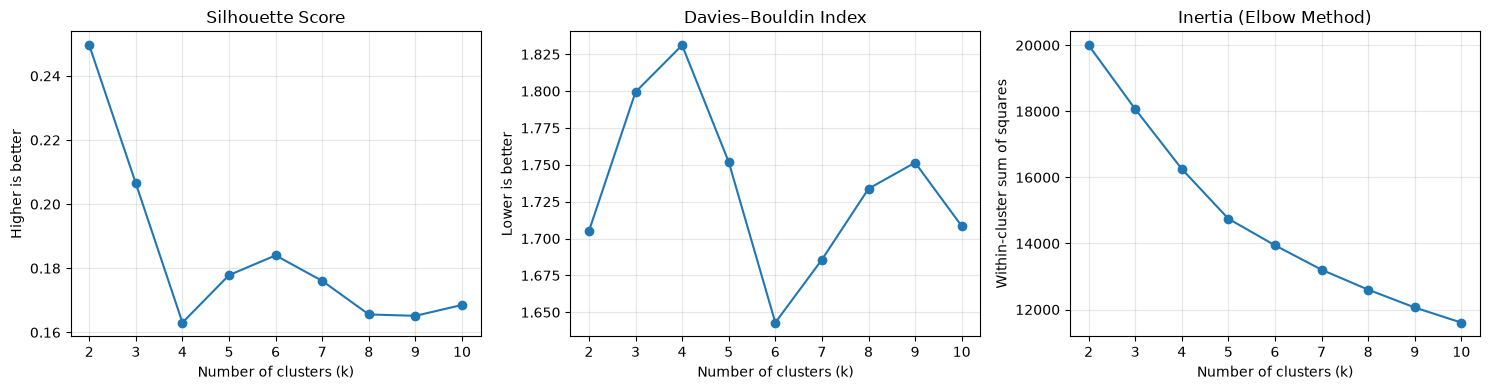

In [8]:

import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

metrics = [
    ("Silhouette_Score", "Silhouette Score"),
    ("Davies_Bouldin_Index", "Davies–Bouldin Index"),
    ("Inertia", "Inertia (Elbow Method)")
]

for ax, (column, title) in zip(axes, metrics):
    ax.plot(
        kmeans_results_df["k"],
        kmeans_results_df[column],
        marker="o"
    )
    ax.set_title(title)
    ax.set_xlabel("Number of clusters (k)")
    ax.set_xticks(kmeans_results_df["k"])
    ax.grid(alpha=0.3)

axes[0].set_ylabel("Higher is better")
axes[1].set_ylabel("Lower is better")
axes[2].set_ylabel("Within-cluster sum of squares")

plt.tight_layout()
plt.show()



### Interpretation of Evaluation Curves

The evaluation curves confirm that no single cluster solution is consistently preferred across all criteria. The inertia curve shows diminishing improvements as k increases, with no sharply defined elbow, although the reduction begins to moderate around k = 4–5. Together with the Silhouette and Davies–Bouldin results, this supports retaining k = 2, 3 and 6 as provisional candidates for further assessment. Final selection will consider cluster stability, preprocessing sensitivity and substantive interpretability.


### Cluster Size Assessment — Candidate K-Means Solutions

In [9]:

# Examine cluster sizes for shortlisted solutions
candidate_k = [2, 3, 6]

cluster_sizes = []

for k in candidate_k:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20
    )

    labels = model.fit_predict(X_standard)

    counts = pd.Series(labels).value_counts().sort_index()

    for cluster, count in counts.items():
        cluster_sizes.append({
            "k": k,
            "Cluster": cluster,
            "Urban_Centres": count,
            "Percentage": count / len(labels) * 100
        })

cluster_size_df = pd.DataFrame(cluster_sizes)

display(cluster_size_df.round(2))


,k,Cluster,Urban_Centres,Percentage
0,2,0,1425,65.61
1,2,1,747,34.39
2,3,0,522,24.03
3,3,1,1380,63.54
4,3,2,270,12.43
5,6,0,421,19.38
6,6,1,349,16.07
7,6,2,714,32.87
8,6,3,215,9.90
9,6,4,404,18.60


### Exploratory Cluster Profiling — Three-Cluster Solution

What distinguishes these clusters?

In [10]:

# Fit the three-cluster solution
k3_model = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=20
)

k3_labels = k3_model.fit_predict(X_standard)

# Profile clusters using original, interpretable values
k3_profiles = df.copy()
k3_profiles["Cluster"] = k3_labels

# Median values of the 12 baseline predictors
k3_medians = (
    k3_profiles
    .groupby("Cluster")[X_baseline.columns]
    .median()
)

display(k3_medians.T.round(4))


Cluster,0,1,2
GH_POP_TOT_2025,1.065477e+05,8.826909e+04,2.633343e+05
SC_GDP_AVG_2020,2.946262e+07,1.183863e+07,2.789274e+07
IN_CIS_ENE_2020,2.570000e-02,0.000000e+00,2.110000e-02
IN_CIS_TEL_2020,0.000000e+00,0.000000e+00,1.400000e-03
fibre_distance_band_km,1.500000e+01,1.000000e+01,5.000000e+00
IN_CIS_TRA_2020,1.120000e-02,3.600000e-03,1.680000e-02
IN_ROA_DEN_2024,1.200000e-02,7.600000e-03,1.280000e-02
SC_SEC_SYT_2020,7.746000e+00,4.772000e+00,8.549500e+00
IN_CIS_EDU_2020,6.000000e-04,0.000000e+00,6.800000e-03
IN_CIS_WAT_2020,0.000000e+00,0.000000e+00,1.000000e-04



### Exploratory Interpretation of the Three-Cluster Solution

The three-cluster solution reveals distinct but overlapping urban infrastructure profiles. Cluster 0 (522 centres; 24.03%) exhibits relatively high median GDP, energy infrastructure and solar PV potential, while Cluster 1 (1,380 centres; 63.54%) has the lowest median GDP, schooling, transport infrastructure and road density, alongside zero median values for several infrastructure indices. Cluster 2 (270 centres; 12.43%) is characterized by larger populations, stronger telecom and education infrastructure indicators, higher schooling levels and closer proximity to mapped terrestrial fibre networks. These differences suggest that urban infrastructure characteristics vary across multiple dimensions rather than following a single readiness hierarchy. The profiles remain exploratory and should not yet be interpreted as validated investment suitability categories.


### Visualize the Three-Cluster Infrastructure Profiles

#### Generate the cluster-profile heatmap

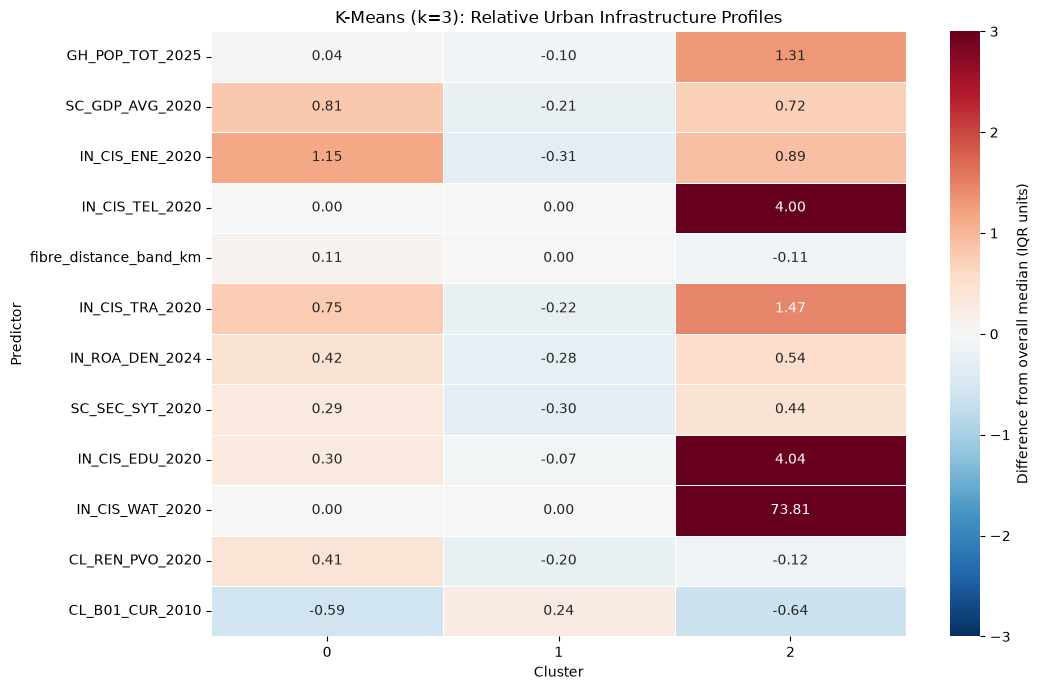

Features excluded from heatmap (zero IQR): []


In [13]:

import matplotlib.pyplot as plt
import seaborn as sns

# Compare cluster medians relative to the overall feature distribution
overall_median = X_baseline.median()
overall_iqr = (
    X_baseline.quantile(0.75) -
    X_baseline.quantile(0.25)
)

# Avoid division by zero for highly sparse indicators
valid_features = overall_iqr[overall_iqr > 0].index

profile_heatmap = (
    k3_medians[valid_features] -
    overall_median[valid_features]
).div(overall_iqr[valid_features])

# Visualize relative cluster profiles
plt.figure(figsize=(11, 7))

sns.heatmap(
    profile_heatmap.T,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    center=0,
    vmin=-3,
    vmax=3,
    linewidths=0.5,
    cbar_kws={"label": "Difference from overall median (IQR units)"}
)

plt.title("K-Means (k=3): Relative Urban Infrastructure Profiles")
plt.xlabel("Cluster")
plt.ylabel("Predictor")
plt.tight_layout()
plt.show()

# Identify features excluded due to zero IQR
excluded_features = overall_iqr[overall_iqr == 0].index.tolist()
print("Features excluded from heatmap (zero IQR):", excluded_features)



**Visualization note:** Cluster profiles are expressed as deviations from the overall feature median, normalized by the interquartile range (IQR). The heatmap colour scale is capped at ±3 IQR units to improve comparability across indicators. Numerical annotations retain the actual normalized values. All 12 predictors are represented.



### Interpretation of the Three-Cluster Profiles

The k = 3 solution reveals distinct socioeconomic, infrastructure and environmental characteristics across African urban centres. Cluster 1 (63.54%) generally exhibits lower infrastructure and socioeconomic indicator values, while Cluster 2 (12.43%) shows relatively higher population, education, transport, telecommunications and water infrastructure indicators, alongside closer proximity to mapped terrestrial fibre. Cluster 0 (24.03%) exhibits intermediate and mixed characteristics, including relatively higher GDP, energy infrastructure and solar PV potential.

The IQR-normalized heatmap highlights substantial differences in selected infrastructure indicators, particularly water infrastructure, where a small overall IQR produces a large standardized deviation. These results provide preliminary evidence of differentiated urban infrastructure profiles, but do not establish objectively validated readiness categories or investment suitability. Further evaluation of cluster stability, preprocessing sensitivity and alternative clustering methods is required.


### Comparative Profiling of Alternative K-Means Solutions (k = 2 and k = 6)

In [14]:

# Compare the shortlisted k = 2 and k = 6 solutions
# using the existing transformed and standardized baseline matrix

comparison_profiles = {}
comparison_sizes = []

for k in [2, 6]:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20
    )

    labels = model.fit_predict(X_standard)

    # Cluster sizes
    counts = pd.Series(labels).value_counts().sort_index()

    for cluster, count in counts.items():
        comparison_sizes.append({
            "k": k,
            "Cluster": cluster,
            "Urban_Centres": count,
            "Percentage": count / len(labels) * 100
        })

    # Cluster medians in original feature units
    profile_df = X_baseline.copy()
    profile_df["Cluster"] = labels

    comparison_profiles[k] = (
        profile_df.groupby("Cluster").median()
    )

# Display cluster sizes
comparison_sizes_df = pd.DataFrame(comparison_sizes)

print("Cluster size comparison:")
display(comparison_sizes_df.round(2))

# Display median profiles
for k in [2, 6]:
    print(f"\nMedian infrastructure profiles: k = {k}")
    display(comparison_profiles[k].T.round(4))


Cluster size comparison:


,k,Cluster,Urban_Centres,Percentage
0,2,0,1425,65.61
1,2,1,747,34.39
2,6,0,421,19.38
3,6,1,349,16.07
4,6,2,714,32.87
5,6,3,215,9.90
6,6,4,404,18.60
7,6,5,69,3.18



Median infrastructure profiles: k = 2


Cluster,0,1
GH_POP_TOT_2025,8.724904e+04,1.458362e+05
SC_GDP_AVG_2020,1.197344e+07,3.016898e+07
IN_CIS_ENE_2020,0.000000e+00,2.590000e-02
IN_CIS_TEL_2020,0.000000e+00,2.000000e-04
fibre_distance_band_km,1.000000e+01,1.000000e+01
IN_CIS_TRA_2020,3.700000e-03,1.340000e-02
IN_ROA_DEN_2024,7.700000e-03,1.230000e-02
SC_SEC_SYT_2020,4.705000e+00,8.153000e+00
IN_CIS_EDU_2020,0.000000e+00,2.000000e-03
IN_CIS_WAT_2020,0.000000e+00,0.000000e+00



Median infrastructure profiles: k = 6


Cluster,0,1,2,3,4,5
GH_POP_TOT_2025,9.990621e+04,7.892514e+04,9.444069e+04,3.724445e+05,1.131136e+05,1.066650e+05
SC_GDP_AVG_2020,3.440540e+07,1.058808e+07,1.022958e+07,3.140690e+07,1.605833e+07,1.447810e+07
IN_CIS_ENE_2020,3.190000e-02,0.000000e+00,1.800000e-03,2.620000e-02,2.400000e-03,6.000000e-03
IN_CIS_TEL_2020,0.000000e+00,0.000000e+00,0.000000e+00,1.800000e-03,0.000000e+00,2.000000e-04
fibre_distance_band_km,2.000000e+01,1.000000e+02,5.000000e+00,5.000000e+00,1.000000e+01,5.000000e+00
IN_CIS_TRA_2020,1.230000e-02,2.300000e-03,4.000000e-03,1.850000e-02,5.400000e-03,6.300000e-03
IN_ROA_DEN_2024,1.200000e-02,5.600000e-03,9.300000e-03,1.320000e-02,7.000000e-03,1.100000e-02
SC_SEC_SYT_2020,8.140000e+00,4.624000e+00,3.166000e+00,8.512000e+00,8.938300e+00,5.214000e+00
IN_CIS_EDU_2020,6.000000e-04,0.000000e+00,1.000000e-04,7.900000e-03,0.000000e+00,5.000000e-04
IN_CIS_WAT_2020,0.000000e+00,0.000000e+00,0.000000e+00,1.000000e-04,0.000000e+00,6.000000e-04



### Interpretation of Alternative K-Means Solutions

The k = 2 solution identifies a broad differentiation between urban centres with relatively lower and higher socioeconomic and infrastructure indicator values. Although straightforward to interpret, this configuration may conceal more specific infrastructure characteristics.

The k = 6 solution provides greater differentiation, with cluster sizes ranging from 69 to 714 urban centres. Median profiles indicate variation in population, GDP, education, energy, transport and connectivity indicators, suggesting potentially distinct infrastructure configurations. However, the additional complexity requires further assessment of cluster stability and substantive interpretability.

Together with the previously examined k = 3 solution, these findings support retaining all three configurations for comparative evaluation rather than selecting a final cluster number solely on internal validation metrics.



### K-Means Initialization Stability Assessment

To evaluate the reproducibility of the shortlisted K-Means solutions (k = 2, 3 and 6), clustering will be repeated using different random seeds while holding the feature matrix, preprocessing strategy, number of clusters and algorithm parameters constant.

Stability will be assessed using the Adjusted Rand Index (ARI), which measures agreement between cluster assignments while accounting for chance and is invariant to arbitrary cluster labels.

Higher ARI values indicate greater consistency across initializations. This assessment examines sensitivity to K-Means initialization only; it does not establish stability under data resampling, alternative preprocessing strategies or independent datasets.


In [15]:

from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score
from itertools import combinations

# Shortlisted cluster configurations
candidate_k = [2, 3, 6]

# Repeated initialization seeds
random_seeds = range(10)

stability_results = []

for k in candidate_k:
    cluster_runs = []

    for seed in random_seeds:
        model = KMeans(
            n_clusters=k,
            random_state=seed,
            n_init=20
        )

        labels = model.fit_predict(X_standard)
        cluster_runs.append(labels)

    # Compare all pairs of clustering runs
    ari_scores = [
        adjusted_rand_score(run_a, run_b)
        for run_a, run_b in combinations(cluster_runs, 2)
    ]

    stability_results.append({
        "k": k,
        "Mean_ARI": sum(ari_scores) / len(ari_scores),
        "Min_ARI": min(ari_scores),
        "Max_ARI": max(ari_scores),
        "Std_ARI": pd.Series(ari_scores).std()
    })

stability_df = pd.DataFrame(stability_results)

display(stability_df.round(4))


,k,Mean_ARI,Min_ARI,Max_ARI,Std_ARI
0,2,1.0000,1.0000,1.0,0.0000
1,3,0.9939,0.9805,1.0,0.0064
2,6,0.9250,0.6803,1.0,0.1225



#### Interpretation of K-Means Initialization Stability

The stability assessment revealed differences in reproducibility across the three shortlisted cluster solutions. The two-cluster solution (k = 2) achieved perfect agreement across repeated initializations (mean ARI = 1.0000), while the three-cluster solution (k = 3) demonstrated exceptionally high stability (mean ARI = 0.9939; minimum = 0.9805).

The six-cluster solution (k = 6) exhibited greater sensitivity to initialization, with a mean ARI of 0.9250, a minimum of 0.6803 and a standard deviation of 0.1225. Although k = 6 previously achieved the lowest Davies–Bouldin Index, its comparatively lower stability highlights a trade-off between cluster differentiation and reproducibility.

These findings strengthen the preliminary case for k = 2 and k = 3, particularly the latter as a potentially useful balance between differentiation and stability. However, initialization stability alone is insufficient for final model selection. Further assessment of preprocessing sensitivity, resampling stability and substantive interpretability is required.



### K-Means Sensitivity to Scaling Strategy

#### Rationale and Experimental Design

The initial K-Means experiment used the transformed 12-feature baseline dataset with StandardScaler. This produced preliminary cluster solutions, from which k = 2, 3 and 6 were shortlisted based on internal evaluation metrics, cluster distributions and interpretability. Subsequent initialization stability analysis showed that k = 2 and k = 3 were highly reproducible, while k = 6 exhibited greater sensitivity to random initialization.

However, K-Means relies on distances between observations, making its results potentially sensitive to feature scaling. StandardScaler standardizes variables using their mean and standard deviation, which can be influenced by extreme observations. This is particularly relevant to the present dataset, where several infrastructure indicators exhibit substantial skewness, zero concentrations and heterogeneous distributions across African urban centres.

To assess the robustness of the preliminary findings, **RobustScaler** is introduced as an alternative preprocessing strategy. Unlike StandardScaler, RobustScaler uses the median and interquartile range (IQR), making its scaling parameters less sensitive to extreme values.

The experiment retains the same 12 predictors, previously selected transformations, K-Means settings and shortlisted cluster numbers (k = 2, 3 and 6). Only the scaling method changes, enabling a controlled comparison.

The evaluation considers:

- **Silhouette Score and Davies–Bouldin Index:** To examine clustering quality under each scaling strategy.
- **Adjusted Rand Index (ARI):** To assess agreement between cluster assignments obtained using StandardScaler and RobustScaler.
- **Cluster sizes:** To identify substantial changes in the distribution of urban centres across clusters.

Because scaling changes the distance geometry, internal evaluation scores across differently scaled feature spaces are not treated as directly equivalent measures of model superiority.

The objective is not to assume that RobustScaler is inherently better, but to determine whether the preliminary infrastructure-readiness profiles are robust to an alternative, theoretically justified preprocessing strategy.

The findings will inform the subsequent comparison with Agglomerative Hierarchical Clustering and the selection of methodological configurations for further investigation.


In [16]:

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score, adjusted_rand_score
import pandas as pd

# Compare scaling strategies for shortlisted cluster solutions
scaling_results = []

for k in [2, 3, 6]:
    standard_model = KMeans(
        n_clusters=k, random_state=42, n_init=20
    )
    robust_model = KMeans(
        n_clusters=k, random_state=42, n_init=20
    )

    standard_labels = standard_model.fit_predict(X_standard)
    robust_labels = robust_model.fit_predict(X_robust)

    scaling_results.append({
        "k": k,
        "Standard_Silhouette": silhouette_score(
            X_standard, standard_labels
        ),
        "Robust_Silhouette": silhouette_score(
            X_robust, robust_labels
        ),
        "Standard_DB": davies_bouldin_score(
            X_standard, standard_labels
        ),
        "Robust_DB": davies_bouldin_score(
            X_robust, robust_labels
        ),
        "ARI_Between_Scalers": adjusted_rand_score(
            standard_labels, robust_labels
        ),
        "Robust_Smallest_Cluster": pd.Series(
            robust_labels
        ).value_counts().min()
    })

scaling_results_df = pd.DataFrame(scaling_results)

display(scaling_results_df.round(4))


,k,Standard_Silhouette,Robust_Silhouette,Standard_DB,Robust_DB,ARI_Between_Scalers,Robust_Smallest_Cluster
0,2,0.2496,0.8685,1.7050,0.4236,0.0838,170
1,3,0.2065,0.8474,1.7994,0.5243,0.1673,46
2,6,0.1840,0.8128,1.6430,0.4834,0.0854,6



#### Interpretation of Scaling Sensitivity Results

The scaling sensitivity experiment revealed substantial differences between StandardScaler and RobustScaler. RobustScaler produced considerably higher Silhouette Scores (0.8128–0.8685) and lower Davies–Bouldin Indices (0.4236–0.5243) across the three shortlisted solutions.

However, agreement between cluster assignments was very low (ARI = 0.0838–0.1673), indicating that the identified urban infrastructure profiles are highly sensitive to the scaling strategy.

RobustScaler also generated relatively small clusters, particularly at k = 6, where the smallest cluster contained only six urban centres. This raises the possibility that some apparently favourable internal evaluation scores reflect the separation of extreme observations rather than broadly representative infrastructure profiles.

The findings demonstrate that scaling choice materially influences the clustering structure. Consequently, RobustScaler cannot be considered superior based on internal metrics alone, especially because these metrics are calculated in differently scaled feature spaces.

For the preliminary methodological comparison, StandardScaler will remain the reference configuration, while RobustScaler is retained as a sensitivity experiment. Further investigation of feature influence and cluster composition is warranted before final preprocessing and model selection.



### Agglomerative Hierarchical Clustering — Preliminary Experiment

#### Rationale and Experimental Design

Following the preliminary K-Means experiments and scaling sensitivity assessment, Agglomerative Hierarchical Clustering is evaluated as an alternative unsupervised learning approach.

Unlike K-Means, which partitions observations around cluster centroids, Agglomerative Clustering progressively merges observations based on their similarity. This provides an alternative approach for investigating the structure of infrastructure-readiness profiles across African urban centres.

For comparability, the initial experiment uses the same transformed and StandardScaler-normalized 12-feature baseline dataset employed in the reference K-Means experiment.

Ward linkage with Euclidean distance is selected as the initial configuration because it seeks to minimize within-cluster variance during successive merges.

The shortlisted cluster numbers (k = 2, 3 and 6) are evaluated using Silhouette Score, Davies–Bouldin Index and cluster-size distributions. Agreement with the corresponding K-Means solutions will subsequently be examined using the Adjusted Rand Index.

The objective is to determine whether the preliminary infrastructure profiles are supported by an alternative clustering algorithm, rather than assuming that the K-Means solutions represent the only meaningful structure in the data.


In [17]:

from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    adjusted_rand_score
)
import pandas as pd

# Preliminary Agglomerative Clustering comparison
agglomerative_results = []

for k in [2, 3, 6]:
    model = AgglomerativeClustering(
        n_clusters=k,
        linkage="ward"
    )

    labels = model.fit_predict(X_standard)

    # Reference K-Means configuration
    kmeans_labels = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20
    ).fit_predict(X_standard)

    agglomerative_results.append({
        "k": k,
        "Silhouette": silhouette_score(X_standard, labels),
        "Davies_Bouldin": davies_bouldin_score(
            X_standard, labels
        ),
        "Smallest_Cluster": pd.Series(
            labels
        ).value_counts().min(),
        "ARI_vs_KMeans": adjusted_rand_score(
            kmeans_labels, labels
        )
    })

agglomerative_results_df = pd.DataFrame(
    agglomerative_results
)

display(agglomerative_results_df.round(4))


,k,Silhouette,Davies_Bouldin,Smallest_Cluster,ARI_vs_KMeans
0,2,0.2433,1.7247,627,0.6780
1,3,0.1337,1.8514,376,0.4171
2,6,0.1450,2.0540,218,0.6150


### Interpretation of Preliminary Agglomerative Clustering Results

Agglomerative Hierarchical Clustering was evaluated using Ward linkage and the same standardized 12-feature dataset employed in the reference K-Means experiment. Across the shortlisted solutions (k = 2, 3 and 6), K-Means consistently achieved higher Silhouette Scores and lower Davies–Bouldin Indices, indicating comparatively more favourable cluster cohesion and separation under the selected evaluation criteria.

The Adjusted Rand Index (ARI) between the two algorithms ranged from 0.4171 to 0.6780, demonstrating partial agreement but meaningful differences in cluster assignments. Agglomerative Clustering generally produced larger minimum cluster sizes, particularly for k = 6, suggesting a different partitioning of urban infrastructure characteristics.

Overall, the preliminary findings favour K-Means under the reference preprocessing configuration. However, the resulting groups should be interpreted as exploratory infrastructure profiles rather than independently validated AI-readiness categories. No established ground-truth classification has been identified for the 2,172 urban centres in this study. Consequently, the credibility of the identified profiles will be assessed through cluster stability, preprocessing robustness, substantive interpretation and comparison with independent infrastructure evidence where available. Establishing investment suitability would require additional feasibility criteria and external validation.


### Summary of Preliminary Clustering Experiments

The preliminary experiments evaluated K-Means and Agglomerative Hierarchical Clustering using 12 transformed infrastructure, socioeconomic and environmental predictors for 2,172 African urban centres. K-Means produced comparatively more favourable internal clustering metrics than Ward-linkage Agglomerative Clustering under the reference StandardScaler configuration. Initialization stability was particularly high for the two- and three-cluster solutions, while the six-cluster solution showed greater sensitivity. However, the RobustScaler experiment revealed substantial changes in cluster assignments, demonstrating that the identified profiles are sensitive to preprocessing choices. Overall, the experiments establish the technical feasibility of identifying differentiated urban infrastructure profiles while highlighting the need for further robustness assessment and substantive interpretation. These findings provide the methodological foundation for the next phase: characterizing and mapping infrastructure profiles, assessing their strengths and constraints, incorporating sustainability considerations, and translating the results into preliminary investment-screening intelligence.
